Individual Model Development - Cole Chmielewski 
In this exercise, I modified my Lab 4 submission to test out OvO and OvR models against our poker prediction dataset.

In [1]:
pip install -r requirements_coursera.txt

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 99.2 MB/s eta 0:00:000 MB/s eta 0:00:01

[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install cvxopt

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
# Import libraries &  Manage the Poker Dataset
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
# Import PyArrow to read the Parquet dataset 
import pyarrow.parquet as pq 
# Import CVX Opt
import cvxopt
import cvxopt.solvers
# Import SciKit tools for splitting and preprocessing data 
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer 
from sklearn.metrics import classification_report, f1_score
# Import the poker dataset 
poker = pq.read_table("TestData.parquet")
# Convert to pandas dataframe
poker = poker.to_pandas()
# Check importing 
#print ("Poker Dataset:", poker.shape)
#print(poker.head())
#----
# Prep Data for Classification
#----
features = ["street","seat","n_players","n_active","big_blind","pot","to_call","stack","max_bet","n_raises"]
poker = poker.dropna(subset=["action","hand_id"])
X = poker[features].copy()
y = poker["action"].astype(int).to_numpy()
groups = poker["hand_id"].to_numpy()
## Convert features to numeric values 
for feature in features:
    X[feature]=pd.to_numeric(X[feature],errors="coerce")
# Add a feature for the cost of calling relative to the pot
X["pot_odds"]=X["to_call"]/(X["pot"]+X["to_call"])
# Add a feature for the stack measured in big blinds for standardization, tracking behavior not money
X["stack_bb"]=X["stack"]/X["big_blind"]
# Replace any applicable NaN
X=X.replace([np.inf,-np.inf],np.nan)
print("Action Distribution:")
print(np.unique(y,return_counts=True))

Action Distribution:
(array([0, 1, 2]), array([200889, 117990,  98273]))


In [4]:
# SVM Class from Lab Sprint 4
def nonlinear_kernel(X, y):
    gamma = 1
    K=np.zeros((X.shape[0],y.shape[0]))
    for i in range(X.shape[0]):
        for j in range(y.shape[0]):
            difference = X[i] -y[j]
            distance = np.dot(difference,difference)
            K[i,j]=np.exp(-gamma*distance)
    
    return K
class SVM(object):

  def __init__(self, kernel=nonlinear_kernel, C=1.0):
    self.kernel = kernel
    self.C = C

  def fit(self, X, y):
      N = X.shape[0] # Training samples
      K=self.kernel(X,X) # Kernel Matrix
      P =np.outer(y,y) * K # Setup the quadratic
      q=-np.ones(N)
      G=np.vstack((np.eye(N),-np.eye(N)))
      h=np.hstack((self.C * np.ones(N),np.zeros(N)))
      A = y.reshape(1,N)
      b=np.array([0.0])
      # Prep the matrices for cvxopt
      P = cvxopt.matrix(P,tc='d')
      q = cvxopt.matrix(q,tc='d')
      G = cvxopt.matrix(G,tc='d')
      h = cvxopt.matrix(h,tc='d')
      A = cvxopt.matrix(A,tc='d')
      b = cvxopt.matrix(b,tc='d')
      # Solve the quadratic 
      solution = cvxopt.solvers.qp(P,q,G,h,A,b)
      # Grab the Lagrange multipliers
      self.alphas = np.array(solution['x']).flatten()
      # Store training data 
      self.X_train = X
      self.y_train = y
      # Choose the suport vectors 
      support_mask = self.alphas > 1e-5
      self.support_vectors = X[support_mask]
      self.support_labels = y[support_mask]
      self.support_alphas = self.alphas[support_mask]

      # Task 2 - Calculate bias using margin support vectors 
      bias_values=[]
      for i in range(N):
          if 1e-5 <self.alphas[i] < self.C- 1e-5:
              total = 0 
              for j in range(N):
                  total+=(self.alphas[j]*y[j]*K[i,j])
              bias_values.append(y[i]-total)
      #self.b =np.mean(bias_values) <- this ran into errors, replacing it with this
      if len(bias_values)>0:
          self.b=np.mean(bias_values)
      else:
          self.b=0.0 # Fallback when no multipliers lie between 0 and C
          

            
      return self

  def predict(self, X):
    # Task 2 - Kernal with support vectors
    K = self.kernel(X, self.support_vectors)
    predictions=[]
    for i in range(X.shape[0]):
        total = 0 
        for j in range(len(self.support_alphas)):
            total += (self.support_alphas[j]*self.support_labels[j]*K[i,j])
        total += self.b # Bias term
        if total >= 0:
            predictions.append(1)
        else:
            predictions.append(-1)
    return np.array(predictions)

  def score(self, X, y):
    predictions = self.predict(X)
    correct = 0
    for i in range(len(y)):
         if predictions[i] == y[i]:
              correct += 1
    accuracy = correct / len(y)
    return accuracy

In [5]:
# Creating the Training and Testing Sets 
splitter = GroupShuffleSplit(n_splits=1,test_size=0.25,random_state=42)
train_index, test_index = next(splitter.split(X,y,groups=groups))
# Create the sets 
X_train=X.iloc[train_index]
y_train=y[train_index]
X_test=X.iloc[test_index]
y_test=y[test_index]
#Preprocess the Features 
imputer = SimpleImputer(strategy="median")
X_train=imputer.fit_transform(X_train)
X_test=imputer.transform(X_test)
#Standardize the Features
scaler = StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)
#Small Scale Test Set
X_train_small=[]
y_train_small=[]
X_test_small=[]
y_test_small=[]
for action in range(3):
    #Find instances of each action
    train=X_train[y_train==action][:500]
    test=X_test[y_test==action][:250]
    X_train_small.extend(train)
    y_train_small.extend([action]*len(train))
    X_test_small.extend(test)
    y_test_small.extend([action]*len(test))
X_train_small=np.array(X_train_small)
y_train_small=np.array(y_train_small)

X_test_small=np.array(X_test_small)
y_test_small=np.array(y_test_small)
print("Training Size:", X_train_small.shape)
print("Testing Size:", X_test_small.shape)

Training Size: (1500, 12)
Testing Size: (750, 12)


In [6]:
#One vs rest test
ovr_models=[]
for action in range(3):
    labels =[]
    for label in y_train_small:
        if label == action:
            labels.append(1)
        else:
            labels.append(-1)
    labels = np.array(labels)
    model=SVM(C=1.0)
    model.fit(X_train_small,labels)
    ovr_models.append(model)
# Make a prediction via the highest decision score
ovr_predictions=[]
for sample in X_test_small:
    scores=[]
    for model in ovr_models:
        K=nonlinear_kernel(sample.reshape(1,-1),model.support_vectors)
        score=np.sum(K[0]*model.support_alphas*model.support_labels)+model.b
        scores.append(score)
    ovr_predictions.append(np.argmax(scores))
ovr_accuracy=np.mean(np.array(ovr_predictions) == y_test_small)
print("Accuracy",ovr_accuracy)

     pcost       dcost       gap    pres   dres
 0: -6.7153e+02 -3.6328e+03  2e+04  3e+00  1e-14
 1: -4.9082e+02 -2.3307e+03  2e+03  7e-02  1e-14
 2: -5.5926e+02 -8.4852e+02  3e+02  9e-03  1e-14
 3: -6.0222e+02 -6.9083e+02  9e+01  2e-03  1e-14
 4: -6.1636e+02 -6.4137e+02  3e+01  5e-04  1e-14
 5: -6.2020e+02 -6.2933e+02  9e+00  1e-04  1e-14
 6: -6.2184e+02 -6.2439e+02  3e+00  9e-06  2e-14
 7: -6.2233e+02 -6.2304e+02  7e-01  2e-06  2e-14
 8: -6.2239e+02 -6.2290e+02  5e-01  8e-07  1e-14
 9: -6.2251e+02 -6.2262e+02  1e-01  1e-07  2e-14
10: -6.2253e+02 -6.2257e+02  4e-02  2e-08  2e-14
11: -6.2254e+02 -6.2255e+02  9e-03  3e-09  1e-14
12: -6.2255e+02 -6.2255e+02  3e-03  6e-10  1e-14
13: -6.2255e+02 -6.2255e+02  1e-03  1e-10  1e-14
14: -6.2255e+02 -6.2255e+02  7e-04  6e-11  1e-14
15: -6.2255e+02 -6.2255e+02  7e-05  5e-12  2e-14
Optimal solution found.
     pcost       dcost       gap    pres   dres
 0: -7.2193e+02 -3.7828e+03  2e+04  3e+00  8e-15
 1: -5.2485e+02 -2.4817e+03  2e+03  8e-02  1e-1

In [7]:
#One vs One
ovo_models = []
for i in range(3):
    for j in range(i+1,3):
        mask = (y_train_small==i)|(y_train_small==j)
        X_pair = X_train_small[mask]
        labels=y_train_small[mask]
        y_pair = []
        for label in labels:
            if label == i:
                y_pair.append(1)
            else:
                y_pair.append(-1)
        y_pair = np.array(y_pair)
        model=SVM(C=1.0)
        model.fit(X_pair,y_pair)
        ovo_models.append((i,j,model))
#Run prediction via majority votin
ovo_predictions =[]
for sample in X_test_small:
    votes = np.zeros(3)
    for i, j, model in ovo_models:
        prediction = model.predict(sample.reshape(1,-1))[0]
        if prediction == 1:
            votes[i]+=1
        else:
            votes[j]+=1
    ovo_predictions.append(np.argmax(votes))
ovo_accuracy=np.mean(np.array(ovo_predictions) == y_test_small)
print("Accuracy",ovo_accuracy)

     pcost       dcost       gap    pres   dres
 0: -3.4130e+02 -2.4244e+03  1e+04  3e+00  5e-15
 1: -2.4574e+02 -1.5420e+03  1e+03  5e-02  6e-15
 2: -2.8612e+02 -4.9165e+02  2e+02  8e-03  5e-15
 3: -3.1389e+02 -3.7044e+02  6e+01  1e-03  5e-15
 4: -3.2163e+02 -3.3990e+02  2e+01  3e-04  6e-15
 5: -3.2457e+02 -3.2941e+02  5e+00  4e-05  6e-15
 6: -3.2542e+02 -3.2705e+02  2e+00  8e-06  6e-15
 7: -3.2577e+02 -3.2614e+02  4e-01  3e-07  7e-15
 8: -3.2586e+02 -3.2595e+02  9e-02  7e-09  7e-15
 9: -3.2588e+02 -3.2590e+02  2e-02  7e-10  5e-15
10: -3.2589e+02 -3.2589e+02  2e-03  3e-11  6e-15
11: -3.2589e+02 -3.2589e+02  3e-04  3e-12  6e-15
Optimal solution found.
     pcost       dcost       gap    pres   dres
 0: -4.9249e+02 -2.5709e+03  1e+04  3e+00  1e-14
 1: -3.5537e+02 -1.7298e+03  2e+03  8e-02  1e-14
 2: -4.0551e+02 -5.8913e+02  2e+02  1e-02  1e-14
 3: -4.4027e+02 -4.8631e+02  5e+01  2e-03  1e-14
 4: -4.4865e+02 -4.6243e+02  1e+01  4e-04  1e-14
 5: -4.5145e+02 -4.5548e+02  4e+00  7e-05  1e-1

In [8]:
#Compare Results 
print("OVR Accuracy=",ovr_accuracy,"| OVO Accuracy=",ovo_accuracy)

OVR Accuracy= 0.596 | OVO Accuracy= 0.604


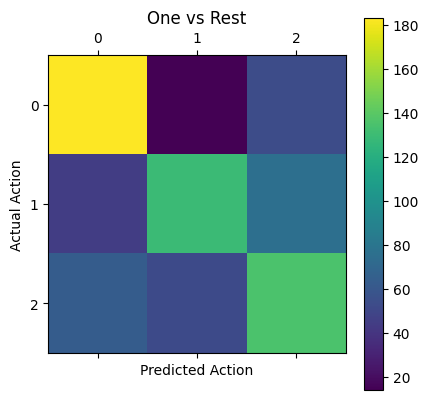

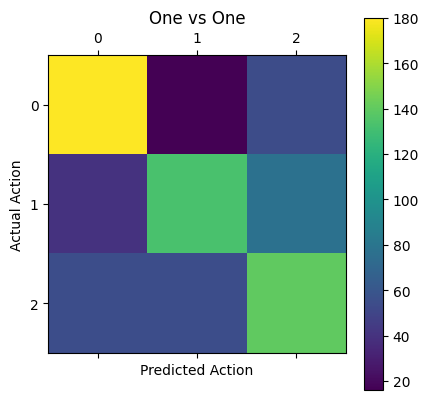

In [9]:
# Plot the Results
# 0 = Fold, 1 = Check/Call, 2 = Bet/Raise
action_names=["Fold","Check/Call","Bet/Raise"]
for predictions, title in[(ovr_predictions,"One vs Rest"),(ovo_predictions,"One vs One")]:
    matrix = np.zeros((3,3))
    for i in range(len(y_test_small)):
        actual = int(y_test_small[i])
        predicted = int(predictions[i])
        matrix[actual,predicted]+=1
    plt.matshow(matrix)
    plt.title(title)
    plt.xlabel("Predicted Action")
    plt.ylabel("Actual Action")
    plt.colorbar()
    plt.show()